<img src="https://github.com/milatovicdanka90-maker/DSB-Unit-03/blob/main/labs/02%20-%20Classification-LeftHanded/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Classification: Predicting Left-Handedness from Psychological Factors

---

One way to define the data science process is as follows:

1. Define the problem.
2. Obtain the data.
3. Explore the data.
4. Model the data.
5. Evaluate the model.
6. Answer the problem.

We'll walk through a full data science problem in this lab.

---
## Step 1: Define The Problem.

You're currently a data scientist working at a university. A professor of psychology is attempting to study the relationship between personalities and left-handedness. They have tasked you with gathering evidence so that they may publish.

As a data scientist, you know that any real data science problem must be **specific** and **conclusively answerable**. For example:
- Bad data science problem: "What is the link between obesity and blood pressure?"
    - This is vague and is not conclusively answerable. That is, two people might look at the conclusion and one may say "Sure, the problem has been answered!" and the other may say "The problem has not yet been answered."
- Good data science problem: "Does an association exist between obesity and blood pressure?"
    - This is more specific and is conclusively answerable. The problem specifically is asking for a "Yes" or "No" answer. Based on that, two independent people should both be able to say either "Yes, the problem has been answered" or "No, the problem has not yet been answered."
- Excellent data science problem: "As obesity increases, how does blood pressure change?"
    - This is very specific and is conclusively answerable. The problem specifically seeks to understand the effect of one variable on the other.

### In the context of the left-handedness and personality example, what are three specific and conclusively answerable problems that you could answer using data science?

> You might find it helpful to check out the codebook in the repo for some inspiration.

In [32]:
# 1. Is there a connection between handedness and personality?

# 2. Do left-handed and right-handed people answer questions about emotions differently?

# 3. Do left-handed and right-handed people have different preferences for mathematics?

---
## Step 2: Obtain the data.

### Read in the file titled "data.csv":
> Hint: Despite being saved as a .csv file, you won't be able to simply `pd.read_csv()` this data!

In [33]:
# library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics

In [34]:
left = pd.read_csv('https://raw.githubusercontent.com/milatovicdanka90-maker/DSB-Unit-03/refs/heads/main/labs/02%20-%20Classification-LeftHanded/data/data.csv', sep="\t")
left.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4184 entries, 0 to 4183
Data columns (total 56 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Q1           4184 non-null   int64 
 1   Q2           4184 non-null   int64 
 2   Q3           4184 non-null   int64 
 3   Q4           4184 non-null   int64 
 4   Q5           4184 non-null   int64 
 5   Q6           4184 non-null   int64 
 6   Q7           4184 non-null   int64 
 7   Q8           4184 non-null   int64 
 8   Q9           4184 non-null   int64 
 9   Q10          4184 non-null   int64 
 10  Q11          4184 non-null   int64 
 11  Q12          4184 non-null   int64 
 12  Q13          4184 non-null   int64 
 13  Q14          4184 non-null   int64 
 14  Q15          4184 non-null   int64 
 15  Q16          4184 non-null   int64 
 16  Q17          4184 non-null   int64 
 17  Q18          4184 non-null   int64 
 18  Q19          4184 non-null   int64 
 19  Q20          4184 non-null 

In [35]:
left.head(10).transpose()

,0,1,2,3,4,5,6,7,8,9
Q1,4,1,1,1,5,5,3,1,1,1
Q2,1,5,2,4,1,4,4,2,5,4
Q3,5,1,1,1,5,2,4,1,1,3
Q4,1,4,1,5,1,2,4,1,2,1
Q5,5,2,5,1,5,1,1,1,2,1
Q6,1,5,4,4,1,1,4,4,4,3
Q7,5,5,3,5,5,3,3,1,3,5
Q8,1,4,2,4,1,3,5,2,2,2
Q9,4,1,1,3,3,3,5,5,2,2
Q10,1,5,4,5,1,1,4,3,3,5


In [36]:
target = "hand" # confirm the exact column name against the codebook
left[target].value_counts(dropna=False)

,count
hand,
1,3542
2,452
3,179
0,11


/tmp/ipykernel_21638/1919808879.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=left, x='hand_label', palette='pastel')


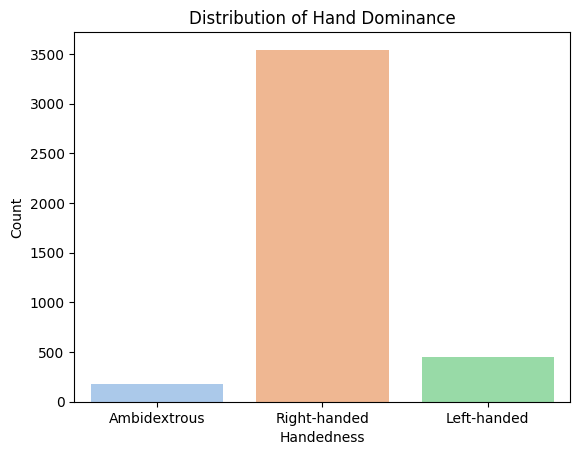

In [37]:
# Map numerical values to strings for cleaner visualization
hand_map = {1: 'Right-handed', 2: 'Left-handed', 3: 'Ambidextrous'}
left['hand_label'] = left['hand'].map(hand_map)

# Plot distribution of hand dominance
sns.countplot(data=left, x='hand_label', palette='pastel')
plt.title("Distribution of Hand Dominance")
plt.xlabel("Handedness")
plt.ylabel("Count")
plt.show()

In [38]:
left.isna().sum().sort_values(ascending=False).head(10)

,0
hand_label,11
Q2,0
Q3,0
Q4,0
Q5,0
Q6,0
Q7,0
Q8,0
Q1,0
Q10,0


In [39]:
left.head()

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand,hand_label
0,4,1,5,1,5,1,5,1,4,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
1,1,5,1,4,2,5,5,4,1,5,...,2,1,14,1,2,2,6,1,1,Right-handed
2,1,2,1,1,5,4,3,2,1,4,...,2,2,30,4,1,1,1,1,2,Left-handed
3,1,4,1,5,1,4,5,4,3,5,...,2,1,18,2,2,5,3,2,2,Left-handed
4,5,1,5,1,5,1,5,1,3,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous


In [40]:
target = "hand_label"   # confirm the exact column name against the codebook
left[target].value_counts(dropna=False)

,count
hand_label,
Right-handed,3542
Left-handed,452
Ambidextrous,179
NaN,11


---

## Step 3: Explore the data.

### Conduct background research:

Domain knowledge is irreplaceable. Figuring out what information is relevant to a problem, or what data would be useful to gather, is a major part of any end-to-end data science project! For this lab, you'll be using a dataset that someone else has put together, rather than collecting the data yourself.

Do some background research about personality and handedness. What features, if any, are likely to help you make good predictions? How well do you think you'll be able to model this? Write a few bullet points summarizing what you believe, and remember to cite external sources.

You don't have to be exhaustive here. Do enough research to form an opinion, and then move on.

> You'll be using the answers to Q1-Q44 for modeling; you can disregard other features, e.g. country, age, internet browser.

In [41]:
left.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4184 entries, 0 to 4183
Data columns (total 57 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Q1           4184 non-null   int64 
 1   Q2           4184 non-null   int64 
 2   Q3           4184 non-null   int64 
 3   Q4           4184 non-null   int64 
 4   Q5           4184 non-null   int64 
 5   Q6           4184 non-null   int64 
 6   Q7           4184 non-null   int64 
 7   Q8           4184 non-null   int64 
 8   Q9           4184 non-null   int64 
 9   Q10          4184 non-null   int64 
 10  Q11          4184 non-null   int64 
 11  Q12          4184 non-null   int64 
 12  Q13          4184 non-null   int64 
 13  Q14          4184 non-null   int64 
 14  Q15          4184 non-null   int64 
 15  Q16          4184 non-null   int64 
 16  Q17          4184 non-null   int64 
 17  Q18          4184 non-null   int64 
 18  Q19          4184 non-null   int64 
 19  Q20          4184 non-null 

### Conduct exploratory data analysis on this dataset:

If you haven't already, be sure to check out the codebook in the repo, as that will help in your EDA process.

You might use this section to perform data cleaning if you find it to be necessary.

In [42]:
left.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Q1,4184.0,1.962715,1.360291,0.0,1.0,1.0,3.00,5.0
Q2,4184.0,3.829589,1.551683,0.0,3.0,5.0,5.00,5.0
Q3,4184.0,2.846558,1.664804,0.0,1.0,3.0,5.00,5.0
Q4,4184.0,3.186902,1.476879,0.0,2.0,3.0,5.00,5.0
Q5,4184.0,2.865440,1.545798,0.0,1.0,3.0,4.00,5.0
Q6,4184.0,3.672084,1.342238,0.0,3.0,4.0,5.00,5.0
Q7,4184.0,3.216539,1.490733,0.0,2.0,3.0,5.00,5.0
Q8,4184.0,3.184512,1.387382,0.0,2.0,3.0,4.00,5.0
Q9,4184.0,2.761233,1.511805,0.0,1.0,3.0,4.00,5.0
Q10,4184.0,3.522945,1.242890,0.0,3.0,4.0,5.00,5.0


In [43]:
left[left["age"]<100]

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand,hand_label
0,4,1,5,1,5,1,5,1,4,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
1,1,5,1,4,2,5,5,4,1,5,...,2,1,14,1,2,2,6,1,1,Right-handed
2,1,2,1,1,5,4,3,2,1,4,...,2,2,30,4,1,1,1,1,2,Left-handed
3,1,4,1,5,1,4,5,4,3,5,...,2,1,18,2,2,5,3,2,2,Left-handed
4,5,1,5,1,5,1,5,1,3,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4179,3,5,4,5,2,4,2,2,2,5,...,1,1,18,2,1,1,6,2,1,Right-handed
4180,1,5,1,5,1,4,2,4,1,4,...,1,1,18,2,2,1,3,2,1,Right-handed
4181,3,2,2,4,5,4,5,2,2,5,...,2,2,22,2,1,1,6,1,1,Right-handed
4182,1,3,4,5,1,3,3,1,1,3,...,2,1,16,1,2,5,1,1,1,Right-handed


In [44]:
left_clean = left[left["age"]<100]

In [45]:
left_cleaned = left_clean[(left_clean != 0).all(axis=1)]

In [46]:
left_cleaned.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Q1,3479.0,1.977005,1.371500,1.0,1.0,1.0,3.0,5.0
Q2,3479.0,3.845070,1.539353,1.0,3.0,5.0,5.0,5.0
Q3,3479.0,2.861742,1.664370,1.0,1.0,3.0,5.0,5.0
Q4,3479.0,3.207531,1.467313,1.0,2.0,3.0,5.0,5.0
Q5,3479.0,2.892498,1.544974,1.0,1.0,3.0,4.0,5.0
Q6,3479.0,3.693590,1.331419,1.0,3.0,4.0,5.0,5.0
Q7,3479.0,3.235412,1.479610,1.0,2.0,3.0,5.0,5.0
Q8,3479.0,3.202357,1.380629,1.0,2.0,3.0,4.0,5.0
Q9,3479.0,2.768037,1.504240,1.0,1.0,3.0,4.0,5.0
Q10,3479.0,3.510204,1.233679,1.0,3.0,4.0,5.0,5.0


### Calculate and interpret the baseline accuracy rate:

In [47]:
left_cleaned['hand'].value_counts(normalize=True).round(2)

,proportion
hand,
1,0.85
2,0.10
3,0.04


In [48]:
baseline_accuracy = left_cleaned['hand'].value_counts(normalize=True).max()
round(baseline_accuracy, 2)

0.85

### Short answer questions:

In this lab you'll use K-nearest neighbors and logistic regression to model
handedness based off of psychological factors.

Answer the following related questions; your answers may be in bullet points
**on your own words**

#### Describe the difference between regression and classification problems:

In [49]:
# Regression is used to predict a numerical value, for example the price of a house, but

# classification is used to predict a category, such as whether a person is left-handed or right-handed, like in this lab.

#### Considering $k$-nearest neighbors, describe the relationship between $k$ and the bias-variance tradeoff:

In [50]:
# When k is small, the model looks at fewer neighbors and can make more mistakes because it is sensitive to individual data points.

# When k is large, the model looks at more neighbors, so predictions are more stable, but it may be less accurate.

# We need to find a good balance to get the best results.

#### Why do we often standardize predictor variables when using $k$-nearest neighbors?

In [51]:
# We standardize predictor variables so that all variables are on a similar scale.
# This is important because KNN uses distances to find the nearest neighbors.

#### Do you think we should standardize the explanatory variables for this problem? Why or why not?

In [52]:
# Yes, we should standardize the variables because they may have different scales.
# This helps KNN compare the answers more fairly.

#### How do we settle on $k$ for a $k$-nearest neighbors model?

In [53]:
# We try different values of k and compare their accuracy. We choose the value that gives the best results on the validation data.

#### What is the default type of regularization for logistic regression as implemented in scikit-learn? (You might [check the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).)

In [54]:
# The default regularization type in scikit-learn's Logistic Regression is L2 regularization.
# It helps prevent the model from becoming too complex.

#### [Bonus - Optional] Describe the relationship between the scikit-learn `LogisticRegression` argument `C` and regularization strength:

#### Describe the relationship between regularization strength and the bias-variance tradeoff:

In [55]:
# Stronger regularization increases bias and decreases variance because the model is simpler and less sensitive to the training data.
# Weaker regularization decreases bias and increases variance because the model can fit the training data more closely.
# We want to find a balance that helps the model make accurate predictions on new data.

#### Logistic regression is considered more interpretable than $k$-nearest neighbors. Explain why.

In [56]:
# Logistic regression is more interpretable because we can look at its coefficients to understand how each variable affects the prediction.
# K-nearest neighbors makes predictions based on nearby data points, so it is harder to explain exactly how each variable influences the result.

---

## Step 4 & 5 Modeling: $k$-nearest neighbors

### Train-test split your data:

Your explanatory variables should be all Q columns.

In [57]:
# 1. Define X (all columns starting with 'Q') and y (the handedness target)
X = left_cleaned[[col for col in left_cleaned.columns if col.startswith('Q')]]
y = left_cleaned['hand']

# 2. Perform the train-test split (using a 80/20 split and setting a random state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale/Standardize the features (crucial for KNN distance calculations!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Instantiate and fit the KNN model
# (Using k=5 as a starting baseline baseline)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("Training complete! Model is ready for evaluation.")

Training complete! Model is ready for evaluation.


### Create and fit four separate $k$-nearest neighbors models:

### Model 1: one with $k = 3$:

In [58]:
# Instantiate KNN model with k = 3
knn_3 = KNeighborsClassifier(n_neighbors=3)

# Fit the model on the scaled training data
knn_3.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_3 = knn_3.score(X_train_scaled, y_train)
test_acc_3 = knn_3.score(X_test_scaled, y_test)

print(f"Model 1 (k=3) Training Accuracy: {train_acc_3 * 100:.2f}%")
print(f"Model 1 (k=3) Testing Accuracy:  {test_acc_3 * 100:.2f}%")

Model 1 (k=3) Training Accuracy: 86.63%
Model 1 (k=3) Testing Accuracy:  82.33%


#### Model 2: one with $k = 5$

In [59]:
# Instantiate KNN model with k = 5
knn_5 = KNeighborsClassifier(n_neighbors=5)

# Fit the model on the scaled training data
knn_5.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_5 = knn_5.score(X_train_scaled, y_train)
test_acc_5 = knn_5.score(X_test_scaled, y_test)

print(f"Model 2 (k=5) Training Accuracy: {train_acc_5 * 100:.2f}%")
print(f"Model 2 (k=5) Testing Accuracy:  {test_acc_5 * 100:.2f}%")

Model 2 (k=5) Training Accuracy: 85.52%
Model 2 (k=5) Testing Accuracy:  84.05%


#### Model 3: one with $k = 15$

In [60]:
# Instantiate KNN model with k = 15
knn_15 = KNeighborsClassifier(n_neighbors=15)

# Fit the model on the scaled training data
knn_15.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_15 = knn_15.score(X_train_scaled, y_train)
test_acc_15 = knn_15.score(X_test_scaled, y_test)

print(f"Model 3 (k=15) Training Accuracy: {train_acc_15 * 100:.2f}%")
print(f"Model 3 (k=15) Testing Accuracy:  {test_acc_15 * 100:.2f}%")

Model 3 (k=15) Training Accuracy: 85.34%
Model 3 (k=15) Testing Accuracy:  85.34%


#### Model 4: one with $k = 25$:

In [61]:
# Instantiate KNN model with k = 25
knn_25 = KNeighborsClassifier(n_neighbors=25)

# Fit the model on the scaled training data
knn_25.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_25 = knn_25.score(X_train_scaled, y_train)
test_acc_25 = knn_25.score(X_test_scaled, y_test)

print(f"Model 4 (k=25) Training Accuracy: {train_acc_25 * 100:.2f}%")
print(f"Model 4 (k=25) Testing Accuracy:  {test_acc_25 * 100:.2f}%")

Model 4 (k=25) Training Accuracy: 85.30%
Model 4 (k=25) Testing Accuracy:  85.34%


### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and
interpret the four scores.

Are any of your models overfit or underfit?

Do any of your models beat the baseline accuracy rate?

---

## Step 4 & 5 Modeling: logistic regression

### Create and fit four separate logistic regression models:

*(Hint: Be careful with how you specify $\alpha$ in your model!)*
Note: You can use the same train and test data as above.

#### Model 1 : one with LASSO and $\alpha = 1$

In [63]:
# Store results for evaluation later
log_reg_results = {}

# Define 4 different values of C (ranging from strong regularization to almost none)
c_values = [0.001, 0.1, 1.0, 100.0]

for i, c_val in enumerate(c_values, start=1):
    # 1. Instantiate the model
    # (Using 'liblinear' solver as it works well for small to medium datasets)
    lr_model = LogisticRegression(C=c_val, solver='liblinear', random_state=42)

    # 2. Fit the model on the scaled training data
    lr_model.fit(X_train_scaled, y_train)

    # 3. Evaluate performance
    train_acc = lr_model.score(X_train_scaled, y_train)
    test_acc = lr_model.score(X_test_scaled, y_test)

    # Save the model and scores
    log_reg_results[f"Model {i}"] = {
        "C": c_val,
        "Regularization": "Strong" if c_val < 1 else ("Moderate" if c_val == 1 else "Weak"),
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
        }

print(f"Model {i} (C={c_val}):")
print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%\n")

Model 4 (C=100.0):
Training Accuracy: 85.30%
Testing Accuracy:  85.34%



#### Model 2 : one with LASSO and $\alpha = 10$

#### Model 3 : one with RIDGE and $\alpha = 1$

#### Model 4 : one with RIDGE and $\alpha = 10$

### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and
interpret the four scores.

Are any of your models overfit or underfit?

Do any of your models beat the baseline accuracy rate?

---

## Step 6: Answer the problem.

Are any of your models worth moving forward with? What are the "best" models?